## Random forest

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score
import numpy as np

housing = pd.read_csv('housing.csv')
housing = housing.fillna(-1)
housing = pd.get_dummies(housing, drop_first=True)
target = 'median_house_value'
X = housing.copy().drop(target, axis=1)
y = housing[target]


### Concepto total de variables

Árbol normal

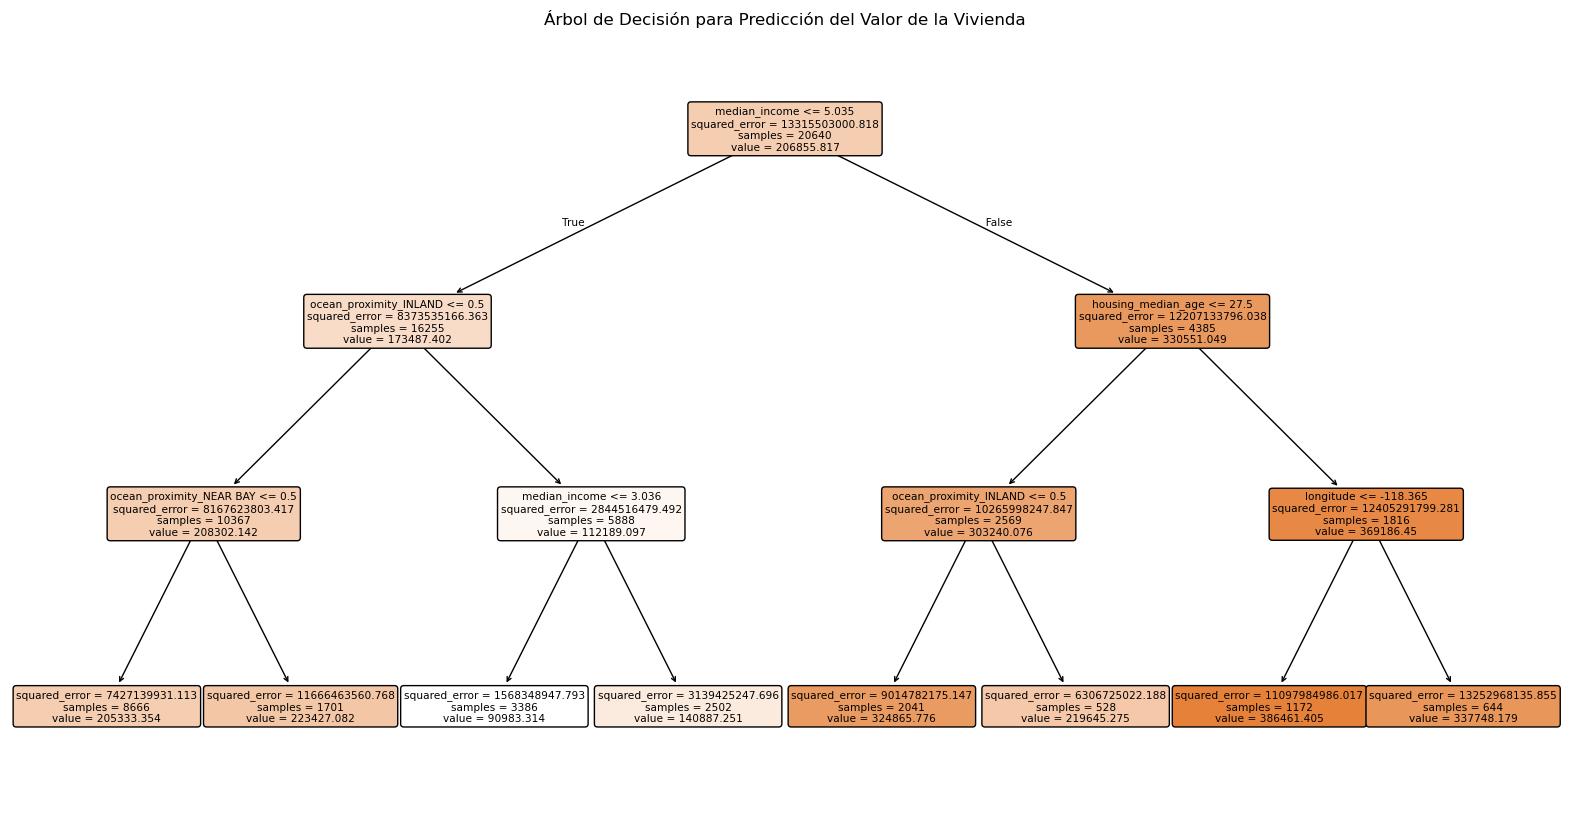

In [2]:
# Train model    
model = DecisionTreeRegressor(max_depth=3, random_state=42, 
                                  max_features='sqrt')
model.fit(X, y)

plt.figure(figsize=(20, 10)) 
plot_tree(model, feature_names=X.keys(), filled=True, rounded=True)
plt.title("Árbol de Decisión para Predicción del Valor de la Vivienda")
plt.show()

### Maximo 3 features

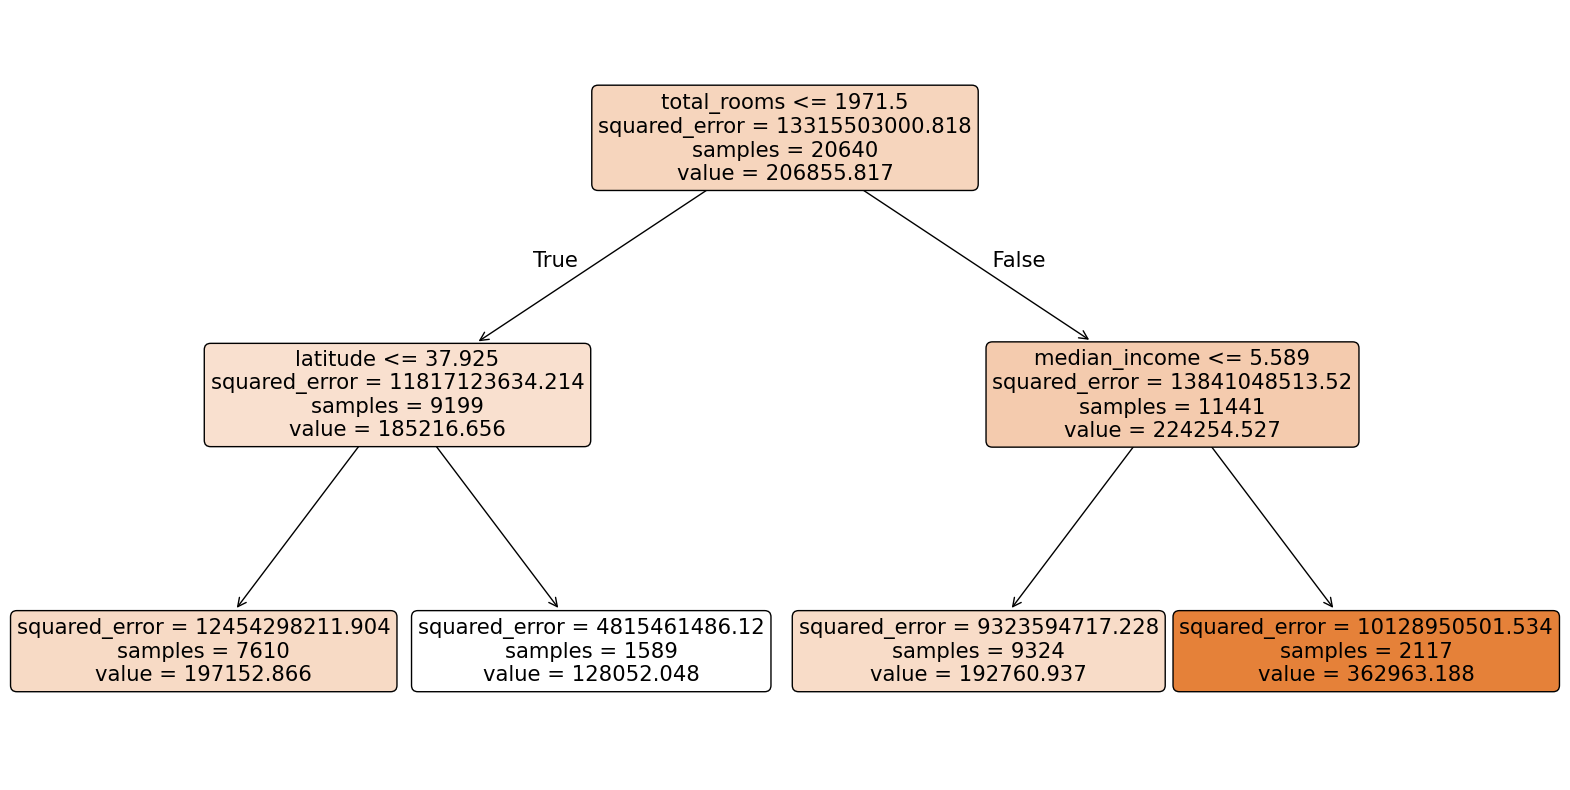

In [3]:
# Crear y entrenar el modelo de árbol de decisión
model = DecisionTreeRegressor(max_depth=2, random_state=1, max_features=3)
model.fit(X, y)

plt.figure(figsize=(20, 10))  # Aumentar tamaño del gráfico
plot_tree(model, feature_names=X.keys(), filled=True, rounded=True)
plt.show()


### Maximo 2 features


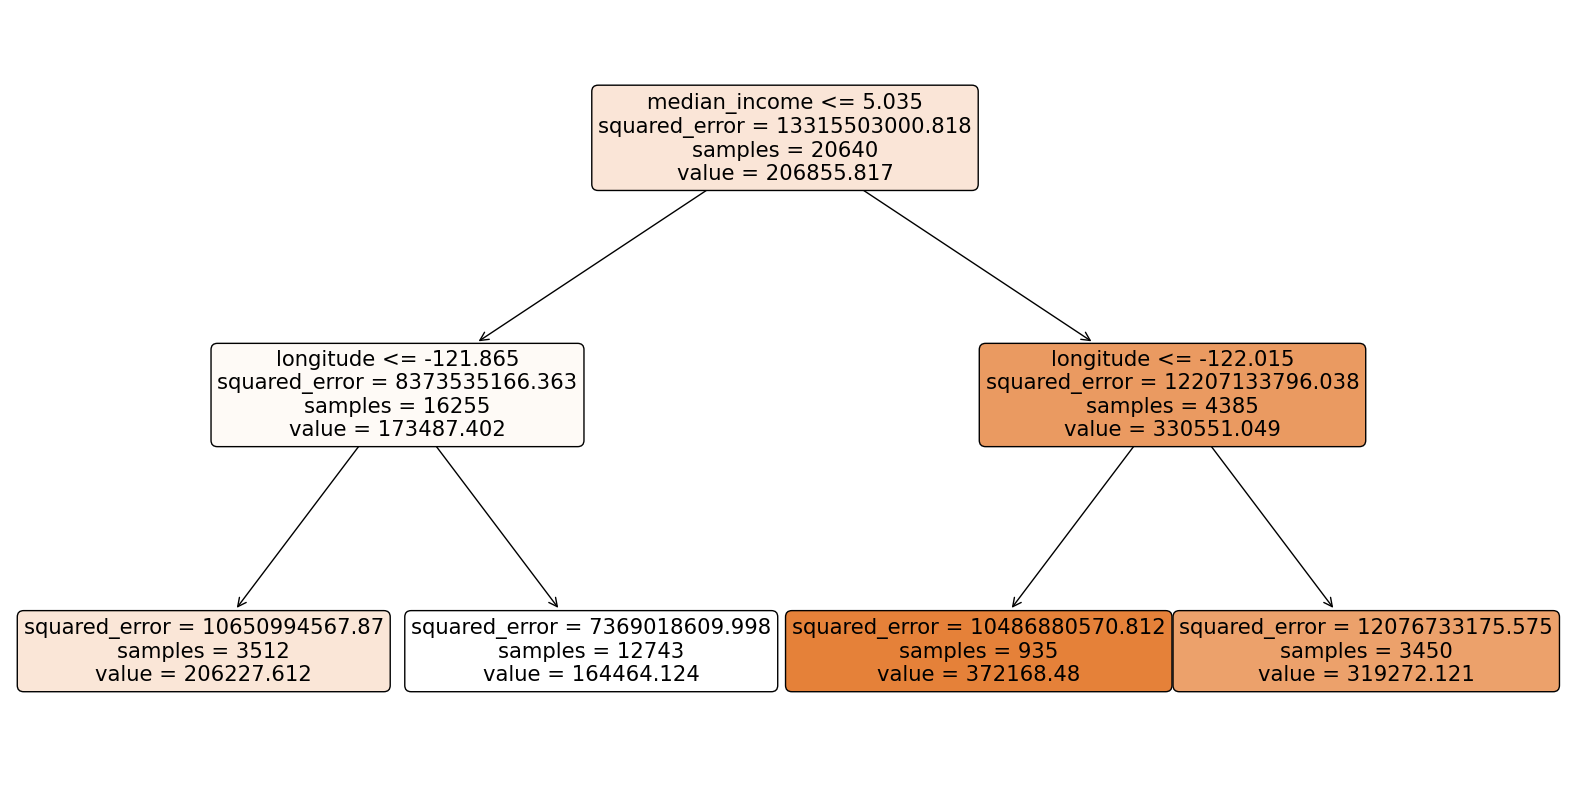

In [4]:
# Crear y entrenar el modelo de árbol de decisión
model = DecisionTreeRegressor(max_depth=2, random_state=42, max_features=2)
model.fit(X, y)

plt.figure(figsize=(20, 10))  # Aumentar tamaño del gráfico
plot_tree(model, feature_names=X.keys(), filled=True, rounded=True)
plt.show()

In [5]:
# Random int
import random
random_int = np.linspace(0, 100, 100)

### Bootstrap tree

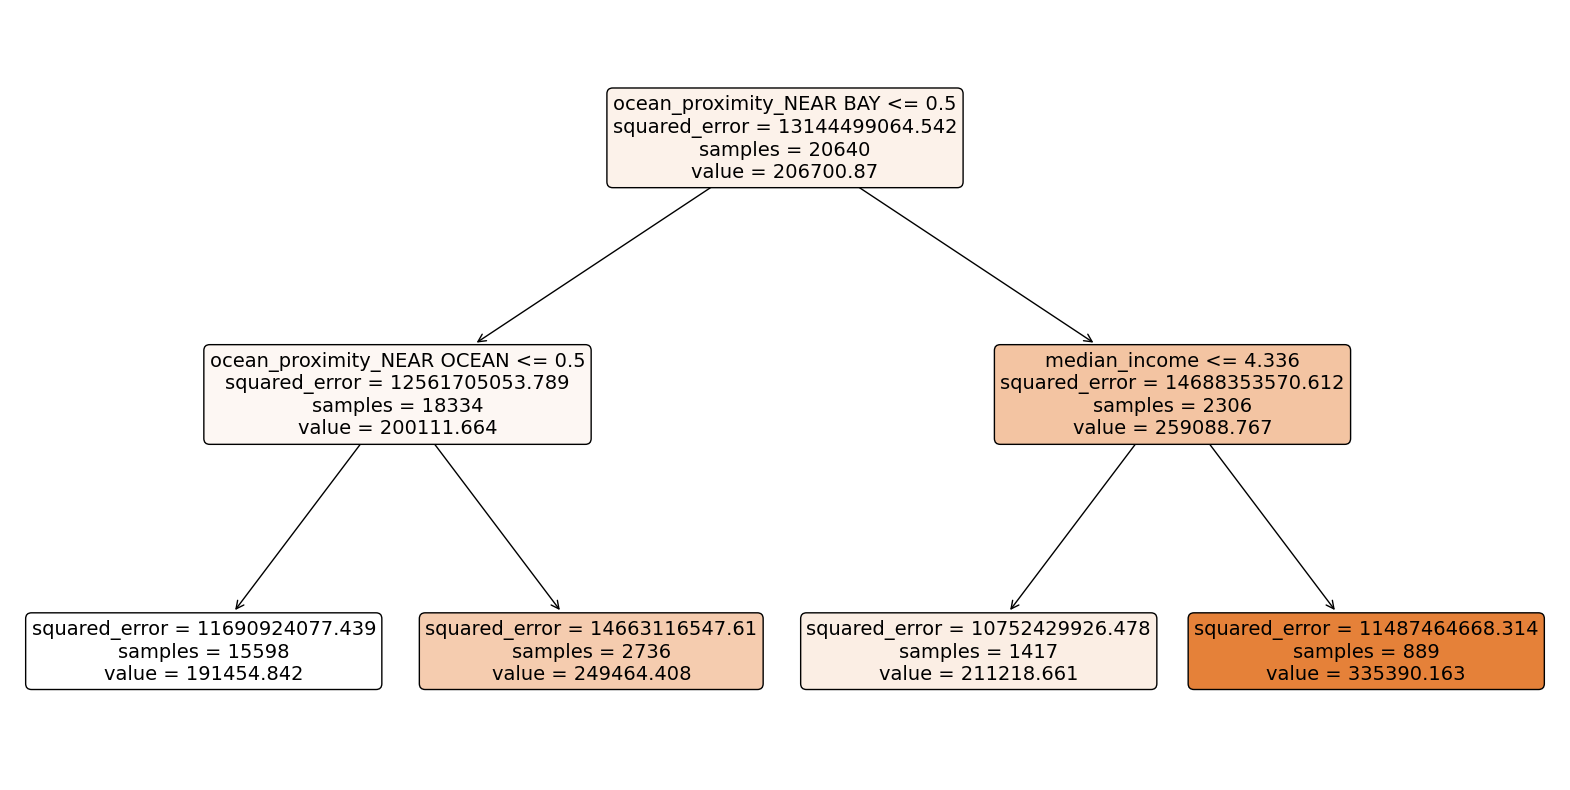

In [6]:
bootstrap_df = housing.sample(len(housing), replace=True)
X = bootstrap_df.drop(target,axis=1)
y = bootstrap_df[target]

# Crear y entrenar el modelo de árbol de decisión
model = DecisionTreeRegressor(max_depth=2, random_state=int(random.choice(random_int)), 
                              max_features='sqrt')
model.fit(X, y)

plt.figure(figsize=(20, 10))  # Aumentar tamaño del gráfico
plot_tree(model, feature_names=X.keys(), filled=True, rounded=True)
plt.show()


### Crea un bosque 

In [7]:
# X train y test
# Dividir en entrenamiento y prueba

df_sample = housing.sample(1000)
X_sample = df_sample.drop(target,axis=1)
y_sample = df_sample[target]

predicciones = pd.DataFrame()
# Crea muchos árboles
for i in range(100):
    # Boostrap ds
    bootstrap_df = housing.sample(len(housing), replace=True)
    X = bootstrap_df.drop(target,axis=1)
    y = bootstrap_df[target]
    # Train model    
    model = DecisionTreeRegressor(max_depth=10, random_state=int(random.choice(random_int)), 
                                  max_features='sqrt')
    model.fit(X, y)
    
    bootstrapped_predictions = model.predict(X_sample)
    predicciones['bootstrap_' + str(i)] = bootstrapped_predictions


In [8]:
predicciones_bosque = predicciones.mean(axis=1)

In [9]:
r2_score(y_pred=predicciones_bosque, y_true=y_sample)

0.8133258675697725

### Usando Sklearn

In [10]:
from sklearn.ensemble import RandomForestRegressor

housing = pd.read_csv('housing.csv')
housing = housing.fillna(-1)
housing = pd.get_dummies(housing, drop_first=True)
target = 'median_house_value'
X = housing.copy().drop(target, axis=1)
y = housing[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [12]:
X_train.keys()

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN'],
      dtype='object')

In [13]:
pipeline = Pipeline([
    ('rf', RandomForestRegressor(n_estimators=300))
])

params = {
    'rf__max_depth': [6, 10, 12, 15, 20],
    'rf__max_features' :['sqrt', 'log2', 10]
}

grid_rf = GridSearchCV(estimator=pipeline, cv=5, n_jobs=-1, param_grid=params, scoring='r2')
grid_rf.fit(X_train, y_train)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('rf',
                                        RandomForestRegressor(n_estimators=300))]),
             n_jobs=-1,
             param_grid={'rf__max_depth': [6, 10, 12, 15, 20],
                         'rf__max_features': ['sqrt', 'log2', 10]},
             scoring='r2')

In [14]:
grid_rf.best_params_

{'rf__max_depth': 20, 'rf__max_features': 10}

In [15]:
best_forest = grid_rf.best_estimator_.named_steps['rf']

In [16]:
predicciones = best_forest.predict(X_test)

In [17]:
r2_score(y_pred=predicciones, y_true=y_test)

0.8184858208024771

In [18]:
# Comparar con regresion lineal 
from sklearn import linear_model

model = linear_model.LinearRegression().fit(X_train, y_train)
predicciones_lm = model.predict(X_test)
# Regresion lineal 
r2_score(y_pred=predicciones_lm, y_true=y_test)

0.6146061359095102

# Interpretacion del modelo

In [19]:
importancia_variables = pd.DataFrame({
    'variable': X_train.keys(),
    'importancia': best_forest.feature_importances_
})
importancia_variables

,variable,importancia
0,longitude,0.107261
1,latitude,0.102687
2,housing_median_age,0.050823
3,total_rooms,0.024851
4,total_bedrooms,0.024018
5,population,0.033074
6,households,0.019643
7,median_income,0.474497
8,ocean_proximity_INLAND,0.152672
9,ocean_proximity_ISLAND,0.000331


## Partial dependence plot


Un Partial Dependence Plot (PDP) muestra la relación entre una o más características y la predicción de un modelo, manteniendo las demás variables fijas. Es útil para entender cómo un modelo como un Random Forest toma decisiones.


In [20]:
from sklearn.inspection import partial_dependence, PartialDependenceDisplay


In [21]:
len(X_train.keys())

12

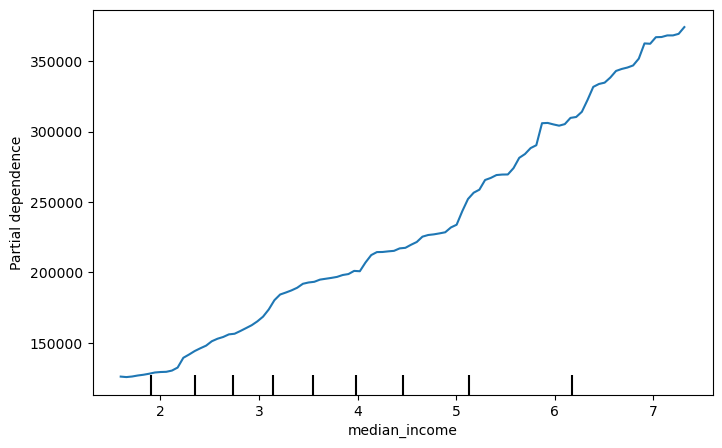

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
PartialDependenceDisplay.from_estimator(best_forest, X_train, [7], ax=ax, feature_names=X_train.keys())
plt.show()

### Partial dependence 3D

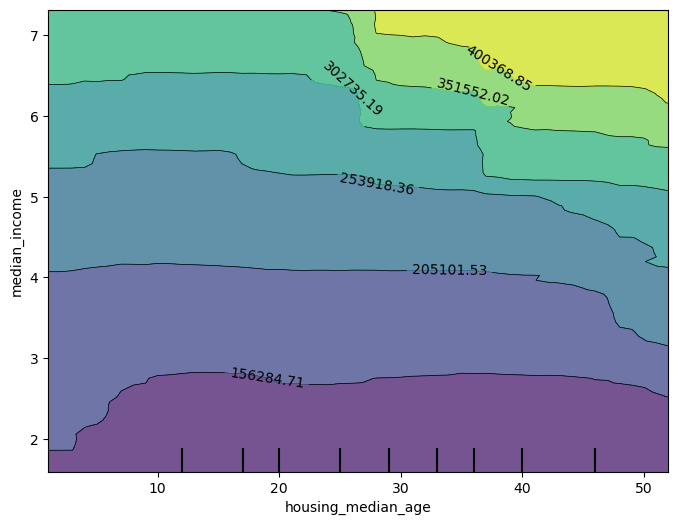

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(best_forest, X_train, [(2, 7)], ax=ax, feature_names=X_train.keys())
plt.show()